# Mixing the image's own entropy gradient into Ramen's step trades zero-shot-wrong images for zero-shot-right ones; the held-out pick (λ = 0.9, unit mix) does not clear the CIFAR-10-C noise floor

*2026-11-27. Week 04. Plan: `docs/plans/grad_mix.md`. Builds on `week_01_2026-11-02/2026-11-06_grad_alignment/grad_alignment.ipynb` (Finding 2: the own entropy gradient $g_H$ is close to the true-label CE gradient on zero-shot-right images and points away from it on zero-shot-wrong ones); does not repeat it.*

**Question.** If Ramen's SignSGD step uses $\lambda\, g_R + (1-\lambda)\, g_H$ instead of $g_R$ alone, is there a $\lambda < 1$ that predicts better than Ramen ($\lambda = 1$)?
**Hypothesis (pre-registered).** The $\lambda$ chosen on the CIFAR-10-C held-out corruptions (seed 0) beats Ramen on the CIFAR-10-C test stream (seed 0) by more than the CIFAR-10-C noise floor (0.184 points).

**Variants** (`ramen_lab.methods.grad_mix.RamenGradMix`, config on top of `cfg/CIFAR10C/Ramen.yaml`; all label-free)
| name | config | what it changes |
|---|---|---|
| GradMix100 | `mix_lambda: 1.0` | nothing: Ramen (identity-checked) |
| GradMixRaw{10,25,50,75,90} | `mix_lambda: 0.1…0.9`, `mix_norm: raw` | step on $\mathrm{sign}(\lambda g_R + (1-\lambda) g_H)$, the literal mix |
| GradMixUnit{10,25,50,75,90} | same, `mix_norm: unit` | step on $\mathrm{sign}(\lambda \hat g_R + (1-\lambda) \hat g_H)$, each term scaled to unit length |
| GradMix0 | `mix_lambda: 0.0` | the own gradient only (one episodic entropy step per image, no memory) |
| NoAdapt | upstream | zero-shot CLIP reference |

**Data.** CIFAR-10-C, severity 5, mixed stream (all domains shuffled into one stream), 10 classes. *Test stream:* the 15 standard corruptions × 10,000 = 150,000 images. *Held-out stream:* the 4 extra corruptions upstream loads with `extra=True` (speckle noise, Gaussian blur, spatter, saturate) × 10,000 = 40,000 images, used only to choose $\lambda$.
**Backbone / batch.** CLIP ViT-B/32, batch 100 (frozen, D18). **Seed.** 0 (a seed changes only the stream order).
**How produced.** `python grad_mix.py run CIFAR10C --domains heldout --seed 0 --noadapt` on the RTX 2080 Ti; `python grad_mix.py run CIFAR10C --seed 0` on the RTX 3080 Ti (the GPU model of the seed-0 Ramen baseline `pc2_C10_Ramen_b100_s0`). Resources in the sanity section.
**What counts (pre-registered).** $\lambda^*$ = the variant with the highest held-out accuracy; stop if it is GradMix100. Gate: $\lambda^*$ minus Ramen seed 0 on the test stream > 0.184. The test-stream curve over all $\lambda$ is diagnostic only.

## How Ramen adapts, and what this experiment changes

For a batch $\{x_i\}$, zero-shot CLIP with LayerNorm affine parameters $\theta_0$, one copy per image (`src/models/ModelForBySampleTTA.py`, `BySampleLayerNorm`):

**1. Embedding, prediction, entropy** (`src/methods/Ramen.py:114-116`): $z_i = f_{\theta_0}(x_i)$, $p_i = \mathrm{softmax}(W^\top z_i)$, $\hat y_i = \arg\max_c p_{ic}$, $H_i = -\sum_c p_{ic}\log p_{ic}$.

**2. Own entropy gradient** (`Ramen.py:118-120`; `RamenStoredValue.compute_values`): $g_H(i) = \nabla_{\theta_i} H_i \big|_{\theta_0} \in \mathbb R^D$.

**3. Memory write, before retrieval** (`Ramen.py:124-133`; `RamenStoredValue.write`): $(z_i, g_H(i), H_i, t_i)$ into queue $\mathcal M_{\hat y_i}$ (capacity 7,500 per class, fp16 FIFO priorities).

**4. Retrieval and aggregation** (`Ramen.py:136-154`; `RamenStoredValue.retrieve`), top-$k$ ($k = 50$) per non-empty queue:
$$w_{ij} = e^{-H_j} e^{-\beta\lVert z_i - z_j\rVert}, \qquad g_R(i) = \frac{1}{|\mathcal C^+|}\sum_{c\in\mathcal C^+}\sum_{j\in\mathrm{top}k_c(z_i)} w_{ij}\, g_H(j)$$

**5. Step, predict, reset** (`Ramen.py:157-168`; SignSGD `src/models/optimizer.py:100-103`, $\eta = 0.01$): $\theta_i = \theta_0 - \eta\,\mathrm{sign}(G_i)$ with $G_i = g_R(i)$ in Ramen.

### The change (`RamenGradMix.retrieve`, `ramen_lab/methods/grad_mix.py`)
$$\boxed{G_i^{\text{raw}} = \lambda\, g_R(i) + (1-\lambda)\, g_H(i)} \qquad \boxed{G_i^{\text{unit}} = \lambda \frac{g_R(i)}{\lVert g_R(i)\rVert} + (1-\lambda)\frac{g_H(i)}{\lVert g_H(i)\rVert}}$$
Only $\mathrm{sign}(G_i)$ reaches the parameters, so the mix decides, coordinate by coordinate, which term wins. In `raw`, $\lambda$ is not the share: with $r_i = \lVert g_R(i)\rVert / \lVert g_H(i)\rVert$ the effective share of $g_R$ is $\lambda r_i / (\lambda r_i + 1 - \lambda)$. In `unit` it is $\lambda$. Note: Ramen writes before it retrieves, so $g_R(i)$ already contains $g_H(i)$ once, with weight $e^{-H_i}/|\mathcal C^+|$; the mix adds more of it.

### What it should do, and how it could fail
From grad_alignment Finding 2: $g_H$ is almost the true-label CE gradient on images zero-shot gets right, and points away from it on images zero-shot gets wrong (toward the wrong argmax). So lowering $\lambda$ should **help zero-shot-right images and hurt zero-shot-wrong ones**. Accuracy moves only through flips, so the net depends on how many zero-shot-wrong images Ramen fixes (lost if the own gradient takes over) against how many zero-shot-right images Ramen breaks (recovered).
Failure modes: (1) the held-out stream (40,000 images) never fills the memory (10 × 7,500), so $\lambda^*$ may not transfer; (2) one seed; (3) fp16: the mixed direction is handed to the optimizer as its sign, so a small mixed coordinate cannot underflow to 0.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parents[2])); sys.path.insert(0, str(HERE))
import grad_mix as gm
from ramen_lab.analysis.plots import use_style
use_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
HELD, TEST = gm.load_stream("heldout"), gm.load_stream("main")
FLOOR = gm.floor_cifar10c()
print(f"held-out runs: {len(HELD)}, test runs: {len(TEST)}, CIFAR-10-C noise floor: {FLOOR:.3f} pts")

held-out runs: 13, test runs: 14, CIFAR-10-C noise floor: 0.184 pts


## The data
Images per domain, and errors of zero-shot CLIP (NoAdapt) and Ramen, before any result. Held-out: Ramen = GradMix100 (identity-checked below).

In [2]:
display(pd.DataFrame(gm.data_table(HELD, "GradMix100")).set_index("domain"))
display(pd.DataFrame(gm.data_table(TEST, "Ramen")).set_index("domain"))
for name, runs, ref in (("held-out", HELD, "GradMix100"), ("test", TEST, "Ramen")):
    zs = gm.zs_correct(runs)
    print(f"{name}: zero-shot right {int(zs.sum()):,} of {len(zs):,} ({zs.mean():.1%}); NoAdapt acc {runs['NoAdapt'].acc:.2f}, Ramen acc {runs[ref].acc:.2f} (mean over domains)")

,images,NoAdapt errors,GradMix100 errors
domain,,,
speckle_noise,"10,000","5,501 (55.0%)","3,656 (36.6%)"
gaussian_blur,"10,000","2,865 (28.6%)","2,206 (22.1%)"
spatter,"10,000","2,037 (20.4%)","1,521 (15.2%)"
saturate,"10,000","1,818 (18.2%)","1,294 (12.9%)"


,images,NoAdapt errors,Ramen errors
domain,,,
gaussian_noise,"10,000","6,137 (61.4%)","3,982 (39.8%)"
shot_noise,"10,000","5,733 (57.3%)","3,708 (37.1%)"
impulse_noise,"10,000","5,718 (57.2%)","4,378 (43.8%)"
defocus_blur,"10,000","2,741 (27.4%)","2,292 (22.9%)"
glass_blur,"10,000","5,612 (56.1%)","3,576 (35.8%)"
motion_blur,"10,000","3,329 (33.3%)","2,252 (22.5%)"
zoom_blur,"10,000","2,828 (28.3%)","2,124 (21.2%)"
snow,"10,000","2,618 (26.2%)","1,908 (19.1%)"
frost,"10,000","2,427 (24.3%)","1,991 (19.9%)"


held-out: zero-shot right 27,789 of 40,000 (69.5%); NoAdapt acc 69.45, Ramen acc 78.31 (mean over domains)
test: zero-shot right 92,067 of 150,000 (61.4%); NoAdapt acc 61.36, Ramen acc 72.61 (mean over domains)


## Sanity checks
**Identity.** λ = 1 must be Ramen. Test stream: against the week-01 baseline run on the same GPU model. Held-out: there is no separate Ramen run; the subset `check` (200 per domain) found GradMix100 identical to plain Ramen on 800 of 800 held-out and 3,000 of 3,000 test predictions (`grad_mix.py check`, 2026-11-27), and `tests/test_lab_grad_mix.py` checks bit identity of the logits.
**Resources** from `metrics.json`. `git dirty` is True for every run: both chains started before the code was committed. The method and runner code they ran is what was then committed unchanged as e28f6d0; later commits to `grad_mix.py` add analysis functions only.

In [3]:
display(pd.DataFrame([gm.identity_row(TEST, "GradMix100", "Ramen")]))
res = pd.DataFrame(gm.sanity_table(HELD) + gm.sanity_table(TEST))
display(res)
print(f"peak RAM max {res['peak RAM (GB)'].max()} GB of a {res['RAM budget (GB)'].max()} GB budget; total {res['minutes'].sum():.0f} GPU-minutes")

,runs,identical predictions,GPUs
0,pc2_C10_GradMix100_b100_s0 vs pc2_C10_Ramen_b1...,"150,000 of 150,000 (100.00%)",RTX 3080 Ti / RTX 3080 Ti


,run,gpu,git dirty,peak RAM (GB),RAM budget (GB),peak GPU alloc (GB),minutes
0,pc2_C10_NoAdapt_b100_s0_heldout,RTX 2080 Ti,True,4.65,10.0,0.55,0.37
1,pc2_C10_GradMix0_b100_s0_heldout,RTX 2080 Ti,True,5.12,10.0,7.77,1.57
2,pc2_C10_GradMixRaw10_b100_s0_heldout,RTX 2080 Ti,True,5.52,10.0,7.77,1.62
3,pc2_C10_GradMixRaw25_b100_s0_heldout,RTX 2080 Ti,True,5.30,10.0,7.77,1.69
4,pc2_C10_GradMixRaw50_b100_s0_heldout,RTX 2080 Ti,True,5.34,10.0,7.77,1.72
5,pc2_C10_GradMixRaw75_b100_s0_heldout,RTX 2080 Ti,True,5.35,10.0,7.77,1.74
6,pc2_C10_GradMixRaw90_b100_s0_heldout,RTX 2080 Ti,True,5.31,10.0,7.77,1.74
7,pc2_C10_GradMix100_b100_s0_heldout,RTX 2080 Ti,True,5.31,10.0,7.77,1.74
8,pc2_C10_GradMixUnit10_b100_s0_heldout,RTX 2080 Ti,True,5.33,10.0,7.77,1.74
9,pc2_C10_GradMixUnit25_b100_s0_heldout,RTX 2080 Ti,False,5.32,10.0,7.77,1.74


peak RAM max 7.83 GB of a 10.0 GB budget; total 69 GPU-minutes


## Finding 1: on the held-out corruptions every λ < 1 is below Ramen except λ = 0.9 with the unit mix, which the pre-registered rule therefore picks
Accuracy (mean over the 4 held-out domains), gain over λ = 1, and fixed / broken images against λ = 1.

In [4]:
held_tbl = pd.DataFrame(gm.sweep_table(HELD)).set_index("variant")
CHOSEN = gm.select_lambda(HELD)
display(held_tbl[["lambda", "mix", "acc", "gain vs lambda=1", "fixed", "broken"]].sort_values("acc", ascending=False).round(3))
print(f"lambda* (pre-registered rule, held-out only): {CHOSEN}")

,lambda,mix,acc,gain vs lambda=1,fixed,broken
variant,,,,,,
GradMixUnit90,0.90,unit,78.505,0.197,1047,968
GradMix100,1.00,-,78.308,0.000,0,0
GradMixRaw90,0.90,raw,77.888,-0.420,1036,1204
GradMixUnit75,0.75,unit,76.922,-1.385,1715,2269
GradMixRaw75,0.75,raw,76.722,-1.585,1587,2221
GradMixRaw50,0.50,raw,75.012,-3.295,1910,3228
GradMixUnit50,0.50,unit,74.305,-4.002,1965,3566
GradMixRaw25,0.25,raw,73.508,-4.800,2017,3937
GradMixUnit25,0.25,unit,73.095,-5.213,2016,4101


lambda* (pre-registered rule, held-out only): GradMixUnit90


## Finding 2: the gate fails: λ* gains +0.11 over Ramen on the test stream, below the 0.184 noise floor, and its 95% CI includes 0
Gain = mean over domains, paired by image against `pc2_C10_Ramen_b100_s0`; CI by cluster bootstrap over base images (one image appears under all 15 corruptions).

In [5]:
gate = gm.gate_row(TEST, CHOSEN, FLOOR)
display(pd.DataFrame([gate]).round(3))

,lambda*,test acc,Ramen acc (baseline seed 0),gain,95% CI,noise floor,passes gate,fixed,broken,both right,both wrong
0,GradMixUnit90,72.724,72.614,0.11,"[-0.03, +0.26]",0.184,False,4369,4204,104717,36710


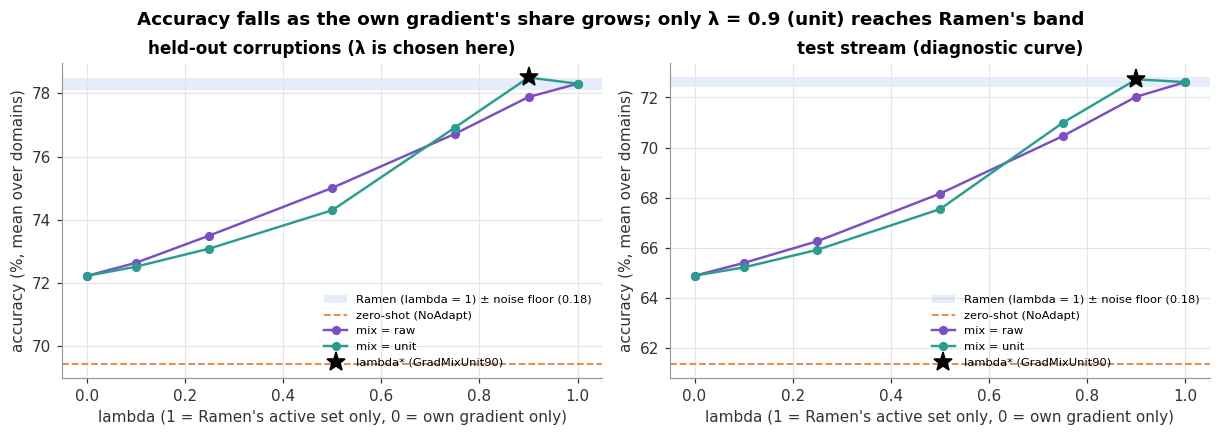

In [6]:
fig = gm.sweep_figure({"held-out corruptions (λ is chosen here)": HELD, "test stream (diagnostic curve)": TEST}, FLOOR, CHOSEN)
fig.suptitle("Accuracy falls as the own gradient's share grows; only λ = 0.9 (unit) reaches Ramen's band", fontweight="bold", y=1.03)
plt.show()

## Finding 3: the mix does what the derivation predicts: it raises accuracy on zero-shot-right images and lowers it, much more, on zero-shot-wrong ones
Test stream, accuracy per image on the two groups (zero-shot correctness from each run's logged zero-shot argmax).

,lambda,mix,acc,gain vs lambda=1,fixed,broken,acc on zs right (%),acc on zs wrong (%)
variant,,,,,,,,
GradMix0,0.00,-,64.88,-7.73,9043,20639,97.06,13.75
GradMixRaw10,0.10,raw,65.39,-7.22,9105,19939,97.13,14.94
GradMixRaw25,0.25,raw,66.26,-6.35,9037,18569,97.15,17.16
GradMixRaw50,0.50,raw,68.16,-4.45,8627,15308,97.04,22.27
GradMixRaw75,0.75,raw,70.46,-2.16,7070,10306,96.15,29.62
GradMixRaw90,0.90,raw,72.03,-0.58,4711,5584,94.54,36.27
GradMix100,1.00,-,72.61,0.00,0,0,90.85,43.64
GradMixUnit10,0.10,unit,65.21,-7.40,9027,20129,97.13,14.48
GradMixUnit25,0.25,unit,65.92,-6.70,9028,19072,97.21,16.19


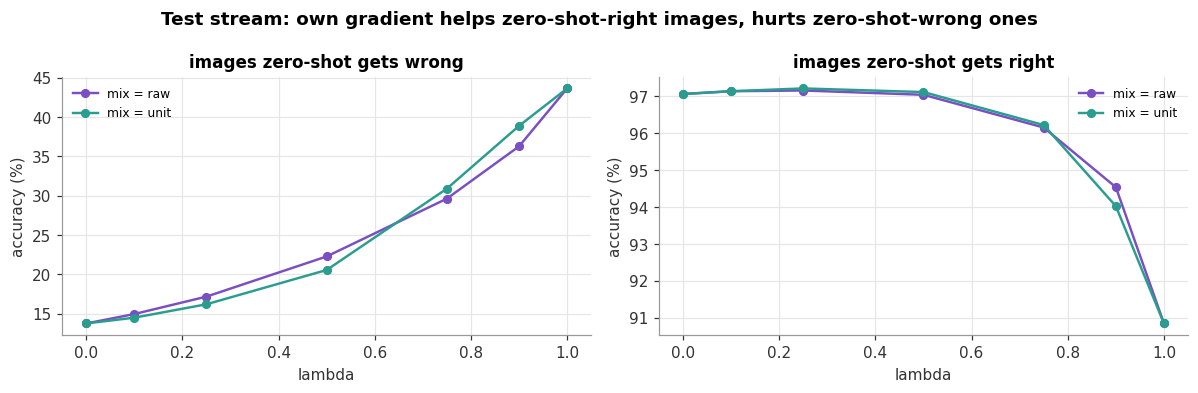

In [7]:
test_tbl = pd.DataFrame(gm.sweep_table(TEST)).set_index("variant")
display(test_tbl[["lambda", "mix", "acc", "gain vs lambda=1", "fixed", "broken", "acc on zs right (%)", "acc on zs wrong (%)"]].round(2))
gm.zs_split_figure(gm.sweep_table(TEST), "Test stream: own gradient helps zero-shot-right images, hurts zero-shot-wrong ones"); plt.show()

## Finding 4: the two gradients have similar lengths, so raw and unit mixes are close; at λ = 0.9 only a few percent of coordinates change sign
Median norm ratio $\lVert g_R\rVert/\lVert g_H\rVert$, the resulting effective share of $g_R$ in the raw mix, and the share of coordinates whose step sign differs from Ramen's (`stored_value.npz`).

In [8]:
display(pd.DataFrame(gm.mechanism_table(TEST)).set_index("variant").round(3))

,lambda,mix,median ||g_R||/||g_H||,median effective share of g_R,median flipped coords vs Ramen,mean flipped coords vs Ramen
variant,,,,,,
GradMix0,0.00,-,0.67,0.000,0.389,0.390
GradMixRaw10,0.10,raw,0.67,0.069,0.361,0.362
GradMixRaw25,0.25,raw,0.67,0.183,0.320,0.318
GradMixRaw50,0.50,raw,0.67,0.401,0.244,0.237
GradMixRaw75,0.75,raw,0.67,0.668,0.138,0.138
GradMixRaw90,0.90,raw,0.67,0.858,0.057,0.062
GradMix100,1.00,-,0.67,1.000,0.000,0.000
GradMixUnit10,0.10,unit,0.67,0.100,0.360,0.362
GradMixUnit25,0.25,unit,0.67,0.250,0.311,0.312


## Interpretation

**What the numbers say.**
- The held-out sweep picked λ = 0.9 with the unit mix, the only setting above λ = 1 there (Finding 1). On the test stream it gains +0.11 points over Ramen, below the 0.184 noise floor, with a 95% CI that includes 0. Fixed and broken images nearly cancel (Finding 2). **The pre-registered gate fails.**
- Every other λ < 1 is below Ramen on both streams, by more the further λ drops. λ = 0 (the own gradient alone) is far below Ramen and a few points above zero-shot (Finding 1, Finding 2 figure).
- The mechanism is the one the derivation predicted (Finding 3). Adding the own gradient raises accuracy on images zero-shot already gets right, and lowers it, by much more, on images zero-shot gets wrong. Ramen's memory average is what fixes a large share of the zero-shot-wrong images. The own entropy gradient instead pushes each image toward its own zero-shot argmax, which confirms the error. Because Ramen fixes more zero-shot-wrong images than it breaks zero-shot-right ones, giving the own gradient more weight loses on net.
- $g_R$ and $g_H$ have similar lengths (median ratio below 1, Finding 4), so the raw mix is close to the unit mix at the same λ. The literal formula was not dominated by one term.

**What they do not say.**
- One seed. The held-out margin of λ* over λ = 1 has no held-out noise floor.
- The held-out stream never fills Ramen's memory, so it is a weaker proxy for the test stream than its size suggests.
- This tests a fixed, global λ. A λ that depends on the image (e.g. more own gradient when the image is likely zero-shot-right) is a different idea, not tested here. It needs a label-free signal of zero-shot correctness, which is the same problem as confidence-based selection [hypothesis].

**Next step.** This direction is stopped on CIFAR-10-C per the pre-registered rule; no seeds 1-4 or held-out datasets. The per-image step-size study (`docs/plans/step_size.md`) keeps Ramen's direction and asks the per-image question for the step length instead. Its stop rule is pre-registered there.

## Glossary
- **$g_H(i)$ (own entropy gradient):** gradient of image $i$'s prediction entropy w.r.t. its own LayerNorm affine copy at $\theta_0$; what Ramen stores in memory.
- **$g_R(i)$ (active-set gradient):** Ramen's retrieved, weighted aggregate of stored $g_H(j)$ (step 4).
- **$G_i$:** the direction whose sign the optimizer steps on. Ramen: $g_R(i)$; here, the mix.
- **λ (`mix_lambda`):** weight of $g_R$ in the mix; 1 = Ramen, 0 = own gradient only.
- **raw / unit mix:** literal weighted sum / weighted sum of the two gradients after scaling each to unit length.
- **Effective share of $g_R$:** $\lambda r/(\lambda r + 1 - \lambda)$ with $r = \lVert g_R\rVert/\lVert g_H\rVert$; equals λ for the unit mix.
- **Flipped coordinates:** share of coordinates where $\mathrm{sign}(G_i)$ differs from Ramen's $\mathrm{sign}(g_R(i))$.
- **Zero-shot right / wrong:** CLIP's prediction before adaptation matches / does not match the label.
- **Fixed / broken:** images wrong under λ = 1 and right under the variant / the reverse.
- **Held-out stream:** the 4 extra CIFAR-10-C corruptions, used only to choose λ (AGENTS.md rule 8).
- **Noise floor:** 2 × (max − min) of Ramen's mean accuracy over seeds 0-4 at the fixed batch (`2026-11-01_baseline/baseline.ipynb`).
- **95% CI:** cluster bootstrap over base images (each CIFAR-10 test image appears under every corruption).
- **$\beta, k, \eta$:** distance temperature (5.0), retrieved entries per queue (50), SignSGD step (0.01), from `cfg/CIFAR10C/Ramen.yaml`.